# Late Fusion — Questionnaire (case A) + Images (Phase 2)

**Thesis:** Early detection of ASD in children aged 8 years or younger using multimodal machine learning

---

## What this notebook does

1. Loads the **per-child outputs** of the two branches, exactly as exported by their notebooks.
2. Shows the **five usual metrics** (Accuracy, Precision, AUROC, Recall, F1) of each branch separately.
3. Fuses both branches through **likelihood ratios** and evaluates the complete system with the same five metrics.
4. Adds an **external reference** (published sensitivity and specificity of the Q-CHAT-10) and a **sensitivity analysis** with the fine-tuned model of Phase 2b.

## Branches used

| Branch | Model | Output that is loaded |
|---|---|---|
| **Questionnaire** | Case A: XGBoost on the 10 Q-CHAT-10 items | `tabular_holdout_scores.csv` (hold-out, n = 110) |
| **Images** | Phase 2: frozen EfficientNetV2B0 + calibrated XGBoost, on the normalized face | `rama_imagenes_salida_fusion.csv` (test, n = 281) |

## What is measured and what is simulated

No child has both modalities, so **the fused system cannot be evaluated on real subjects**. It is evaluated on a **simulated paired cohort**, built from the real outputs of each branch.

| Element | Nature |
|---|---|
| Metrics of each branch separately | **Measured** (own hold-out and test) |
| Score distribution of the image branch | **Measured** (resampled from the real test set) |
| Pairing between modalities | **Simulated** |
| Metrics of the fused system | **Derived** from the above |

## Warning about the questionnaire branch

In the own cohort, the `ASD_traits` label was derived from the Q-CHAT-10 rule itself. The case A metrics are therefore **inflated by construction** and must be read as an **upper bound**. Section 5 contrasts them with the published sensitivity and specificity (Allison et al., 2012).

> **Repository `asd-screening-audit` · Notebook 5 of 5 — Late fusion on a simulated paired cohort**
>
> Academic research on early ASD screening with public data. **This is not a diagnostic tool** and its results must not be used for clinical decisions.

| | |
|---|---|
| **Run order** | Notebooks 01 → 02 → 03 → 04 → 05. Notebook 05 requires the outputs of 01, 03 and 04 (optional); 01 and 02 are independent of each other. |
| **Inputs** | From `outputs/rama_tabular/`: `tabular_holdout_scores.csv`, `tabular_oof_scores.csv`, `metadatos_ejecucion.json`. From `outputs/rama_imagenes_fase2/`: `rama_imagenes_salida_fusion.csv`, `rama_imagenes_parametros.json`. Optional, from `outputs/rama_imagenes_fase2b/`: `fase2b_salida_test.csv`. |
| **Outputs** | In `outputs/fusion/`: tables 1 to 4, sensitivities, `umbral_independiente.csv`, figures and `resumen_fusion_casoA.json`. |
| **Hardware** | CPU |
| **Data** | Source, license and folder layout: see `data/README.md` in the repository. |
| **Reproducibility** | Global seed `SEED = 42`. The first code cell defines `PROJECT_DIR`; there are no other hard-coded paths. |

*File and folder names are kept in Spanish so that they match the original runs and the article.*


---
## 1. Environment and Loading of the Outputs

The notebook looks for each file in the output folder of the previous notebooks (`outputs/rama_tabular`, `outputs/rama_imagenes_fase2` and `outputs/rama_imagenes_fase2b`). **If it finds more than one copy, it uses the most recent one and says so**, so as not to read an old version by mistake.

Results are saved in `outputs/fusion`.

In [1]:
# ==============================================================================
# CELL 1: Environment, Drive mounting and loading of the branch outputs
# ==============================================================================
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, brier_score_loss

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
SEED = 42

# Project paths. Only adjust PROJECT_DIR
# (outside Colab, set the environment variable ASD_PROJECT_DIR).
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = "/content/drive/MyDrive/asd-screening-audit"
except ImportError:
    PROJECT_DIR = os.environ.get("ASD_PROJECT_DIR", ".")

OUTPUTS_ROOT = os.path.join(PROJECT_DIR, "outputs")
OUTPUTS_DIR  = os.path.join(OUTPUTS_ROOT, "fusion")
os.makedirs(OUTPUTS_DIR, exist_ok=True)
print(f"Results in: {OUTPUTS_DIR}\n")

CAND_TAB  = [os.path.join(OUTPUTS_ROOT, "rama_tabular")]
CAND_IMG  = [os.path.join(OUTPUTS_ROOT, "rama_imagenes_fase2")]
CAND_IMG2 = [os.path.join(OUTPUTS_ROOT, "rama_imagenes_fase2b")]

def resolver(nombre, candidatos, obligatorio=True):
    """Locates a file; if there are several copies it uses the most recent one and warns."""
    hallados = [os.path.join(d, nombre) for d in candidatos
                if os.path.exists(os.path.join(d, nombre))]
    if not hallados:
        msg = f"[FALTA] {nombre}\n         searched in: {candidatos}"
        if obligatorio:
            raise FileNotFoundError(msg)
        print(msg); return None
    elegido = max(hallados, key=os.path.getmtime)
    if len(hallados) > 1:
        print(f"[!] {nombre}: there are {len(hallados)} copies. The most recent one is used:")
        for h in hallados:
            print(f"      {h}   ({pd.Timestamp(os.path.getmtime(h), unit='s')})")
    print(f"[OK] {nombre}   <-  {os.path.dirname(elegido)}")
    return elegido

print("Loading branch outputs:")
ho = pd.read_csv(resolver("tabular_holdout_scores.csv", CAND_TAB), index_col=0)
p_oof = resolver("tabular_oof_scores.csv", CAND_TAB, obligatorio=False)
oof = pd.read_csv(p_oof, index_col=0) if p_oof else None
p_meta = resolver("metadatos_ejecucion.json", CAND_TAB, obligatorio=False)
UMBRAL_A = json.load(open(p_meta)).get('umbral_operativo') if p_meta else None
im = pd.read_csv(resolver("rama_imagenes_salida_fusion.csv", CAND_IMG))
p_par = resolver("rama_imagenes_parametros.json", CAND_IMG, obligatorio=False)
par_img = json.load(open(p_par)) if p_par else {}
p_im2 = resolver("fase2b_salida_test.csv", CAND_IMG2, obligatorio=False)
im2 = pd.read_csv(p_im2) if p_im2 else None

# The exported column is called 'score_qchat_calibrado', but case A has NO
# calibration step: it is the raw XGBoost probability.
if 'score_qchat_calibrado' in ho.columns:
    ho = ho.rename(columns={'score_qchat_calibrado': 'prob_xgb_cruda'})
    print("\n[i] 'score_qchat_calibrado' renamed to 'prob_xgb_cruda' (it is not calibrated).")

print(f"\nQuestionnaire hold-out : {len(ho)} children | ASD: {ho.etiqueta_real.mean()*100:.1f}%")
print(f"Image test set        : {len(im)} children | ASD: {im.etiqueta_real.mean()*100:.1f}%")
print(f"Case A operating threshold: {UMBRAL_A}")

Mounted at /content/drive
Results in: /content/drive/MyDrive/asd-screening-audit/outputs/fusion_casoA

Loading branch outputs:
[OK] tabular_holdout_scores.csv   <-  /content/drive/MyDrive/asd-screening-audit/outputs/rama_tabular
[OK] tabular_oof_scores.csv   <-  /content/drive/MyDrive/asd-screening-audit/outputs/rama_tabular
[OK] metadatos_ejecucion.json   <-  /content/drive/MyDrive/asd-screening-audit/outputs/rama_tabular
[OK] rama_imagenes_salida_fusion.csv   <-  /content/drive/MyDrive/asd-screening-audit/outputs/rama_imagenes_fase2
[OK] rama_imagenes_parametros.json   <-  /content/drive/MyDrive/asd-screening-audit/outputs/rama_imagenes_fase2
[OK] fase2b_salida_test.csv   <-  /content/drive/MyDrive/asd-screening-audit/outputs/rama_imagenes_fase2b

[i] 'score_qchat_calibrado' renamed to 'prob_xgb_cruda' (it is not calibrated).

Questionnaire hold-out : 110 children | ASD: 67.3%
Image test set        : 281 children | ASD: 50.2%
Case A operating threshold: 0.62


### Environment versions

In [ ]:
# Environment versions (for the Methods section and requirements.txt)
import sys, platform, importlib.metadata as md
print("Python", sys.version.split()[0], "|", platform.platform())
for p in ["numpy", "pandas", "scipy", "scikit-learn", "xgboost", "tensorflow", "keras",
          "opencv-python", "imagehash", "shap", "statsmodels", "matplotlib", "seaborn",
          "joblib", "Pillow"]:
    try: print(f"{p:<16}{md.version(p)}")
    except Exception: print(f"{p:<16}(not installed)")
try:
    import tensorflow as tf; print("GPU:", [d.name for d in tf.config.list_physical_devices('GPU')])
except Exception: pass


---
## 2. Metrics of Each Branch

### 2.1 Definitions

From the confusion matrix (TP, FP, FN, TN):

$$\text{Accuracy}=\frac{TP+TN}{N},\qquad \text{Precision}=\frac{TP}{TP+FP},\qquad \text{Recall}=\frac{TP}{TP+FN},\qquad F_1=\frac{2\cdot \text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

$$\text{AUROC}=P\big(s(x^+)>s(x^-)\big)$$

Specificity, negative predictive value, balanced accuracy $\tfrac{1}{2}(\text{Recall}+\text{Specificity})$, Matthews correlation coefficient (MCC) and Brier score are added.

### 2.2 How to read the table

- The questionnaire **AUROC** is computed on the raw XGBoost probability; the image one, on the calibrated probability.
- **Precision, Accuracy and F1 depend on the prevalence** of each set (≈ 67 % in the questionnaire hold-out and ≈ 50 % in the image test set). Therefore **the rows are not comparable with each other**.
- The confidence intervals are 95 % Wilson intervals.

In [2]:
# ==============================================================================
# CELL 2: Metrics of each branch separately
# ==============================================================================
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z*z/n
    c = (p + z*z/(2*n)) / d
    h = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d
    return c - h, c + h

def conteos(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return int(tp), int(fp), int(fn), int(tn)

def metricas(y, pred, score=None):
    """Classification metrics. AUROC with continuous 'score' if provided;
    otherwise, on the binary decision (equivalent to (Se + Sp) / 2)."""
    y = np.asarray(y); pred = np.asarray(pred).astype(int)
    tp, fp, fn, tn = conteos(y, pred); n = tp + fp + fn + tn
    rec  = tp/(tp+fn) if tp+fn else np.nan
    prec = tp/(tp+fp) if tp+fp else np.nan
    esp  = tn/(tn+fp) if tn+fp else np.nan
    vpn  = tn/(tn+fn) if tn+fn else np.nan
    f1   = 2*prec*rec/(prec+rec) if (prec + rec) else np.nan
    den  = np.sqrt(float(tp+fp) * (tp+fn) * (tn+fp) * (tn+fn))
    mcc  = (tp*tn - fp*fn)/den if den > 0 else np.nan
    auc  = roc_auc_score(y, score if score is not None else pred)
    return dict(n=n, VP=tp, FP=fp, FN=fn, VN=tn, Accuracy=(tp+tn)/n, Precision=prec,
                AUROC=auc, Recall=rec, F1=f1, Especificidad=esp, VPN=vpn,
                ExactBal=(rec+esp)/2, MCC=mcc)

COLS5 = ['Accuracy', 'Precision', 'AUROC', 'Recall', 'F1']

def mostrar(df, extra=()):
    d = df.copy()
    for c in ['Accuracy', 'Precision', 'Recall', 'F1', *extra]:
        if c in d: d[c] = (d[c] * 100).round(2)
    if 'AUROC' in d: d['AUROC'] = d['AUROC'].round(4)
    if 'Flagged (%)' in d: d['Flagged (%)'] = d['Flagged (%)'].round(2)
    print(d.to_string(index=False))

# --- Case A (hold-out) and images (test) ---
col_a = 'prob_xgb_cruda' if 'prob_xgb_cruda' in ho.columns else None
m_a = metricas(ho.etiqueta_real, ho.prediccion, ho[col_a] if col_a else None)
m_i = metricas(im.etiqueta_real, im.prediccion, im.prob_calibrada)
m_a['Brier'] = brier_score_loss(ho.etiqueta_real, ho[col_a]) if col_a else np.nan
m_i['Brier'] = brier_score_loss(im.etiqueta_real, im.prob_calibrada)

tabla_ramas = pd.DataFrame([
    {'Rama': 'Questionnaire — case A (hold-out)', 'n': m_a['n'], **{c: m_a[c] for c in COLS5}},
    {'Rama': 'Images — Phase 2 (test)',          'n': m_i['n'], **{c: m_i[c] for c in COLS5}},
])
print("=" * 104)
print(" TABLE 1 — METRICS OF EACH BRANCH (held-out sets, threshold fixed on training/validation)")
print("=" * 104)
mostrar(tabla_ramas)
print("=" * 104)

# --- Complement ---
comp = pd.DataFrame([
    {'Rama': 'Questionnaire — case A', 'VP': m_a['VP'], 'FP': m_a['FP'], 'FN': m_a['FN'], 'VN': m_a['VN'],
     'Specificity': m_a['Specificity'], 'VPN': m_a['VPN'], 'Balanced acc.': m_a['ExactBal'],
     'MCC': m_a['MCC'], 'Brier': m_a['Brier']},
    {'Rama': 'Images — Phase 2', 'VP': m_i['VP'], 'FP': m_i['FP'], 'FN': m_i['FN'], 'VN': m_i['VN'],
     'Specificity': m_i['Specificity'], 'VPN': m_i['VPN'], 'Balanced acc.': m_i['ExactBal'],
     'MCC': m_i['MCC'], 'Brier': m_i['Brier']}])
for c in ['Specificity', 'VPN', 'Balanced acc.']: comp[c] = (comp[c]*100).round(2)
comp['MCC'] = comp['MCC'].round(3); comp['Brier'] = comp['Brier'].round(4)
print("\n TABLE 1b — COMPLEMENTARY METRICS")
print(comp.to_string(index=False))

# --- Confidence intervals ---
print("\n 95% CONFIDENCE INTERVALS (Wilson)")
for nom, m in [("Questionnaire — case A", m_a), ("Images — Phase 2", m_i)]:
    for etq, k, n in [("Accuracy", m['VP']+m['VN'], m['n']), ("Precision", m['VP'], m['VP']+m['FP']),
                      ("Recall", m['VP'], m['VP']+m['FN']), ("Specificity", m['VN'], m['VN']+m['FP'])]:
        lo, hi = wilson(k, n)
        print(f"   {nom:<24} {etq:<14} {k/n*100:6.2f}%   [{lo*100:5.1f} , {hi*100:5.1f}]")

# --- Check against the reference runs ---
print("\n CHECK AGAINST THE REFERENCE RUNS")
ref_a = (74, 1, 0, 35)
print(f"   Case A, matrix (TP, FP, FN, TN) = {(m_a['VP'], m_a['FP'], m_a['FN'], m_a['VN'])} "
      f"| referencia {ref_a} | {'COINCIDE' if (m_a['VP'], m_a['FP'], m_a['FN'], m_a['VN']) == ref_a else 'NO COINCIDE: revisar la ruta'}")
print(f"   Images, AUROC = {m_i['AUROC']:.4f} | referencia 0.9091 | "
      f"{'COINCIDE' if abs(m_i['AUROC'] - 0.9091) < 5e-4 else 'NO COINCIDE: revisar la ruta'}")

# --- Case A sensitivity: cross-validation at the operating threshold ---
if oof is not None and UMBRAL_A is not None:
    m_o = metricas(oof.etiqueta_real, (oof.score_qchat_oof >= UMBRAL_A).astype(int), oof.score_qchat_oof)
    print(f"\n CASE A — out-of-fold predictions (CV, n={m_o['n']}) at the operating threshold {UMBRAL_A}:")
    print("   The threshold was chosen with these same data, so they are somewhat optimistic.")
    mostrar(pd.DataFrame([{'Evaluation': 'CV (OOF)', **{c: m_o[c] for c in COLS5}}]))

# --- External reference: Allison at the hold-out prevalence ---
prev_ho = ho.etiqueta_real.mean(); se_l, sp_l = 0.91, 0.89
tp_, fn_, fp_, tn_ = se_l*prev_ho, (1-se_l)*prev_ho, (1-sp_l)*(1-prev_ho), sp_l*(1-prev_ho)
pr_l = tp_/(tp_+fp_)
ref = pd.DataFrame([{'Rama': f'Questionnaire — Allison reference (prev. {prev_ho*100:.1f}%)',
                     'n': np.nan, 'Accuracy': tp_+tn_, 'Precision': pr_l, 'AUROC': (se_l+sp_l)/2,
                     'Recall': se_l, 'F1': 2*pr_l*se_l/(pr_l+se_l)}])
print("\n EXTERNAL REFERENCE (computed, not measured in the own cohort):")
mostrar(ref)
tabla_ramas.to_csv(os.path.join(OUTPUTS_DIR, "tabla1_metricas_por_rama.csv"), index=False)
comp.to_csv(os.path.join(OUTPUTS_DIR, "tabla1b_metricas_complementarias.csv"), index=False)

 TABLE 1 — METRICS OF EACH BRANCH (held-out sets, threshold fixed on training/validation)
                            Rama   n  Accuracy  Precision  AUROC  Recall    F1
Questionnaire — case A (hold-out) 110     99.09      98.67 1.0000  100.00 99.33
        Images — Phase 2 (test) 281     80.43      76.22 0.9091   88.65 81.97

 TABLE 1b — COMPLEMENTARY METRICS
                 Rama  VP  FP  FN  VN  Specificity    VPN  Balanced acc.   MCC  Brier
Questionnaire — case A  74   1   0  35          97.22 100.00              98.61 0.979 0.0118
    Images — Phase 2 125  39  16 101          72.14  86.32              80.40 0.617 0.1276

 95% CONFIDENCE INTERVALS (Wilson)
   Questionnaire — case A    Accuracy        99.09%   [ 95.0 ,  99.8]
   Questionnaire — case A    Precision       98.67%   [ 92.8 ,  99.8]
   Questionnaire — case A    Recall         100.00%   [ 95.1 , 100.0]
   Questionnaire — case A    Specificity   97.22%   [ 85.8 ,  99.5]
   Images — Phase 2        Accuracy        80.43%   [ 

---
## 3. Fusion Parameters

### 3.1 Likelihood ratios

$$LR^+ = \frac{\text{Se}}{1-\text{Sp}}, \qquad LR^- = \frac{1-\text{Se}}{\text{Sp}}$$

### 3.2 Continuity correction for case A

In the hold-out, case A had no false negatives, so $LR^-=0$ exactly. That would drive the posterior probability to absolute zero after a negative result, something no real clinical instrument has. The Haldane-Anscombe correction is applied, which adds 0.5 to each cell of the matrix:

$$\widehat{\text{Se}}=\frac{TP+0.5}{TP+FN+1},\qquad \widehat{\text{Sp}}=\frac{TN+0.5}{TN+FP+1}$$

### 3.3 Case A enters as a binary test

The continuous score of case A grows with the sum of items (≈ 0.92 with sum 4 and ≈ 0.999 with sum 7). Converting it into a likelihood ratio would produce astronomical values and fusion would stop making sense. Its **decision** at the operating threshold enters instead.

### 3.4 Image branch

The full calibrated probability is used. If the model was calibrated on a cohort with prevalence $\pi_0$:

$$LR(s)=\frac{p/(1-p)}{\pi_0/(1-\pi_0)}$$

This conversion is monotonic, so the AUROC does not change. For the AND and OR rules, its binary decision is used, reconstructed with the same threshold as the model.

In [3]:
# ==============================================================================
# CELL 3: Fusion parameters
# ==============================================================================
def razones(se, sp):
    lp = se / (1 - sp) if sp < 1 else np.inf
    ln = (1 - se) / sp if sp > 0 else np.inf
    return lp, ln

# --- Case A: hold-out with continuity correction ---
TP_A, FP_A, FN_A, TN_A = conteos(ho.etiqueta_real, ho.prediccion)
SE_A_CRUDO, SP_A_CRUDO = TP_A/(TP_A+FN_A), TN_A/(TN_A+FP_A)
SE_A = (TP_A + .5) / (TP_A + FN_A + 1)
SP_A = (TN_A + .5) / (TN_A + FP_A + 1)

# --- Reference: Allison et al. (2012) ---
SE_L, SP_L = 0.91, 0.89

# --- Images: test, decision at the model threshold ---
TP_I, FP_I, FN_I, TN_I = conteos(im.etiqueta_real, im.prediccion)
SE_I, SP_I = TP_I/(TP_I+FN_I), TN_I/(TN_I+FP_I)

def preparar_imagen(df, nombre):
    """Converts the calibrated probabilities of an image branch into the
    material the simulation needs: LR per class and decision threshold."""
    y = df.etiqueta_real.values
    p = np.clip(df.prob_calibrada.values, 1e-4, 1 - 1e-4)
    pred = df.prediccion.values.astype(int)
    odds_cal = y.mean() / (1 - y.mean())
    lr = (p / (1 - p)) / odds_cal
    pos, neg = p[pred == 1], p[pred == 0]
    if pos.min() <= neg.max():
        print(f"[!] {nombre}: the binary decision is not separable by threshold; check the CSV.")
    thr = (pos.min() + neg.max()) / 2
    def h_silverman(v):                      # bandwidth on the log scale
        lg = np.log(v); return 1.06 * lg.std() * len(lg) ** (-1 / 5)
    return dict(nombre=nombre, pool0=np.sort(lr[y == 0]), pool1=np.sort(lr[y == 1]),
                h0=h_silverman(lr[y == 0]), h1=h_silverman(lr[y == 1]),
                lr_thr=thr / (1 - thr) / odds_cal, thr_p=thr,
                auc=roc_auc_score(y, p), n=len(y), lr_min=lr.min(), lr_max=lr.max(),
                se=((pred == 1) & (y == 1)).sum() / (y == 1).sum(),
                sp=((pred == 0) & (y == 0)).sum() / (y == 0).sum())

IMG = preparar_imagen(im, "Phase 2 (frozen)")
IMG2B = preparar_imagen(im2, "Phase 2b (fine-tuned)") if im2 is not None else None

print("=" * 96)
print(" BRANCH PARAMETERS FOR FUSION")
print("=" * 96)
print(f"{'Rama':<46}{'Se':>8}{'Sp':>8}{'LR+':>10}{'LR-':>10}")
print("-" * 96)
for n_, se, sp in [("Questionnaire case A (hold-out, corrected)", SE_A, SP_A),
                   ("Questionnaire case A (hold-out, raw)",     SE_A_CRUDO, SP_A_CRUDO),
                   ("Questionnaire reference (Allison 2012)",    SE_L, SP_L),
                   ("Images Phase 2 (test)",                    SE_I, SP_I)]:
    lp, ln = razones(se, sp)
    print(f"{n_:<46}{se:>8.4f}{sp:>8.4f}{lp:>10.2f}{ln:>10.4f}")
print("=" * 96)
print(f" Image threshold (calibrated probability): {IMG['thr_p']:.4f}"
      f"{'  | JSON: ' + str(par_img.get('umbral')) if par_img else ''}")

# Check of the lexicographic ordering assumption (used in section 6)
salto_q = razones(SE_A, SP_A)[0] / razones(SE_A, SP_A)[1]
rango_i = IMG['lr_max'] / IMG['lr_min']
print(f"\n Questionnaire jump (LR+/LR-): {salto_q:,.0f} | image range: {rango_i:.1f}")
print(f" {'The image can NOT reverse the questionnaire: the order is questionnaire first, then image.' if rango_i < salto_q else 'The image can cross the questionnaire jump.'}")

 BRANCH PARAMETERS FOR FUSION
Rama                                                Se      Sp       LR+       LR-
------------------------------------------------------------------------------------------------
Questionnaire case A (hold-out, corrected)       0.9933  0.9595     24.50    0.0069
Questionnaire case A (hold-out, raw)           1.0000  0.9722     36.00    0.0000
Questionnaire reference (Allison 2012)          0.9100  0.8900      8.27    0.1011
Images Phase 2 (test)                          0.8865  0.7214      3.18    0.1573
 Image threshold (calibrated probability): 0.3660  | JSON: 0.3676

 Questionnaire jump (LR+/LR-): 3,526 | image range: 70.4
 The image can NOT reverse the questionnaire: the order is questionnaire first, then image.


---
## 4. Simulated Paired Cohort and Fused System

### 4.1 Procedure

For each virtual child $j$:

1. **True state:** $y_j\sim\text{Bernoulli}(\pi)$.
2. **Questionnaire:** positive with probability $\widehat{\text{Se}}$ if $y_j=1$, or $1-\widehat{\text{Sp}}$ if $y_j=0$.
3. **Image:** a value is drawn from the **real** empirical distribution of $LR$ of class $y_j$ in the test set.
4. **Ordering smoothing:** to rank within the probability fusion, Gaussian noise is added on the log scale (Silverman bandwidth per class), without leaving the observed range. **The binary decisions** (AND rule, OR rule, image alone) use the original value and keep exactly the measured sensitivity and specificity.
5. **Product fusion:**

$$\text{odds}_j=\frac{\pi}{1-\pi}\cdot LR_q(j)\cdot LR_i(j),\qquad p_j=\frac{\text{odds}_j}{1+\text{odds}_j}$$

### 4.2 Configurations evaluated

| Configuration | Decision |
|---|---|
| Questionnaire alone | Binary decision of case A |
| Images alone | Binary decision at the model threshold |
| **AND rule** | Positive if **both** branches are positive |
| **OR rule** | Positive if **either** branch is positive |
| **Posterior — Youden** | Threshold that maximizes $\text{Se}+\text{Sp}-1$ |
| **Posterior — Max. F1** | Threshold that maximizes F1 |
| **Posterior — High precision** | Highest threshold with Recall ≥ 85 % |
| **Posterior — Rule-out** | Highest threshold with Recall ≥ 99 % |

It is evaluated at two prevalences: **50 %**, comparable to that of the test sets, and **1 %**, close to the population one.

The thresholds of the probability fusion are chosen on the simulated cohort itself, so they are illustrative operating points, not validated thresholds.

> **Why the smoothing.** A set of 281 children has very short tails: the few ASD cases with the highest scores may end up above all the controls, which shows a perfect separation that is not real. Without smoothing, the "Max. F1" and "High precision" points would come out with inflated precision.

In [4]:
# ==============================================================================
# CELL 4: Simulation and evaluation of the configurations
# ==============================================================================
def simular(prev, N, se_q, sp_q, img, rho=0.0, semilla=SEED, suavizar=True):
    """Virtual cohort with both modalities.
    rho: conditional correlation between branches (0 = independence)."""
    r = np.random.default_rng(semilla)
    y = (r.random(N) < prev).astype(int)
    if rho == 0.0:
        u1, u2 = r.random(N), r.random(N)
    else:
        z = r.multivariate_normal([0, 0], [[1, rho], [rho, 1]], size=N)
        u1 = norm.cdf(z[:, 0])
        u2 = 1.0 - norm.cdf(z[:, 1])      # complementary quantile: low u1 (questionnaire +)
                                          # is paired with a HIGH-score image
    q = np.where(y == 1, u1 < se_q, u1 < (1 - sp_q)).astype(int)
    lr_i = np.empty(N)
    for c, pool in ((0, img['pool0']), (1, img['pool1'])):
        m = (y == c)
        lr_i[m] = pool[np.clip((u2[m] * len(pool)).astype(int), 0, len(pool) - 1)]
    i_pos = (lr_i >= img['lr_thr']).astype(int)      # binary decision: ORIGINAL value
    lr_raw = lr_i.copy()                             # original value, for the image own AUROC
    if suavizar:                                     # continuous ordering: smoothed value
        h = np.where(y == 1, img['h1'], img['h0'])
        lr_i = np.clip(lr_i * np.exp(r.normal(0, 1, N) * h), img['lr_min'], img['lr_max'])
    lp, ln = razones(se_q, sp_q)
    lr_q = np.where(q == 1, lp, ln)
    odds = (prev / (1 - prev)) * lr_q * lr_i
    return dict(y=y, q=q, i_pos=i_pos, lr_i=lr_i, lr_raw=lr_raw, post=odds / (1 + odds))

def tabla_configuraciones(prev, N, se_q, sp_q, img, rho=0.0, semilla=SEED):
    s = simular(prev, N, se_q, sp_q, img, rho, semilla)
    y, post = s['y'], s['post']
    filas = []
    def fila(nombre, pred, score=None):
        m = metricas(y, pred, score)
        filas.append({'Configuration': nombre, 'Accuracy': m['Accuracy'],
                      'Precision': m['Precision'], 'AUROC': m['AUROC'],
                      'Recall': m['Recall'], 'F1': m['F1'],
                      'Flagged (%)': (m['VP'] + m['FP']) / len(y) * 100})
    fila("Questionnaire alone", s['q'])
    fila("Images alone", s['i_pos'], score=s['lr_raw'])
    fila("Fusion — AND rule (both +)", s['q'] & s['i_pos'])
    fila("Fusion — OR rule (either +)", s['q'] | s['i_pos'])

    # Operating points on the posterior probability (vectorized)
    f, t, th = roc_curve(y, post, drop_intermediate=False)
    npos, nneg = y.sum(), (1 - y).sum()
    tp, fp = t * npos, f * nneg
    prec = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    f1 = np.divide(2 * prec * t, prec + t, out=np.zeros_like(t), where=(prec + t) > 0)
    validos = np.where(t > 0)[0]
    k_youden = validos[np.argmax((t - f)[validos])]
    k_f1 = validos[np.argmax(f1[validos])]
    c85 = validos[t[validos] >= 0.85]; k_hp = c85[np.argmax(prec[c85])]
    c99 = validos[t[validos] >= 0.99]; k_de = c99[np.argmax(prec[c99])]
    for nombre, k in [("Posterior fusion — Youden", k_youden),
                      ("Posterior fusion — Max. F1", k_f1),
                      ("Posterior fusion — High precision (Recall ≥ 85%)", k_hp),
                      ("Posterior fusion — Rule-out (Recall ≥ 99%)", k_de)]:
        fila(nombre, (post >= th[k]).astype(int), score=post)
    return pd.DataFrame(filas)

PREVS = [(0.50, 300_000), (0.01, 1_000_000)]
RES = {}
for prev, N in PREVS:
    RES[prev] = tabla_configuraciones(prev, N, SE_A, SP_A, IMG)
    print("=" * 112)
    print(f" TABLE 2 — FUSED SYSTEM (case A + Phase 2 images) | prevalence {prev*100:.0f}% | simulated n = {N:,}")
    print("=" * 112)
    mostrar(RES[prev])
    print("=" * 112)

# Automatic reading: does the image change the Youden point?
r1 = RES[0.01]
solo_q = r1.loc[r1['Configuration'] == 'Questionnaire alone', 'Flagged (%)'].iloc[0]
youd = r1.loc[r1['Configuration'] == 'Posterior fusion — Youden', 'Flagged (%)'].iloc[0]
print(f"\n Flagged at 1% prevalence: questionnaire alone {solo_q:.2f}% | fusion (Youden) {youd:.2f}%")
if abs(solo_q - youd) < 0.3:
    print(" The Youden point of the fusion coincides with that of the questionnaire alone: the image")
    print(" does not change that operating point; it improves the RANKING (AUROC) and enables")
    print(" more demanding points (AND rule, high precision). This is expected when the questionnaire")
    print(" is already almost perfect because of the information leakage.")

 TABLE 2 — FUSED SYSTEM (case A + Phase 2 images) | prevalence 50% | simulated n = 300,000
                                   Configuration  Accuracy  Precision  AUROC  Recall    F1  Flagged (%)
                               Questionnaire alone     97.68      96.13 0.9768   99.36 97.72         51.64
                                   Images alone     80.40      76.04 0.9089   88.72 81.89         58.29
                      Fusion — AND rule (both +)     93.54      98.77 0.9353   88.16 93.16         44.59
                     Fusion — OR rule (either +)     84.55      76.41 0.8456   99.93 86.60         65.34
                       Posterior fusion — Youden     97.73      96.57 0.9950   98.96 97.75         51.20
                      Posterior fusion — Max. F1     97.73      96.57 0.9950   98.96 97.75         51.20
Posterior fusion — High precision (Recall ≥ 85%)     92.04      98.92 0.9950   85.00 91.43         42.93
      Posterior fusion — Rule-out (Recall ≥ 99%)     97.68      96.13

---
## 5. External Reference and Sensitivity With Phase 2b

### 5.1 Reference with the published sensitivity and specificity

The fusion is repeated replacing case A with the values of Allison et al. (2012). It is the **representative reading of the instrument's diagnostic performance**, whereas case A only provides an upper bound.

### 5.2 Sensitivity with the fine-tuned model

Phase 2b (fine-tuning) showed no statistically distinguishable improvement over the frozen model. The fusion is repeated with its probabilities to verify that the choice of image branch **hardly moves the result**.

In [5]:
# ==============================================================================
# CELL 5: Allison reference and sensitivity with Phase 2b
# ==============================================================================
FILAS_CLAVE = ["Questionnaire alone", "Fusion — AND rule (both +)", "Posterior fusion — Youden",
               "Posterior fusion — High precision (Recall ≥ 85%)"]
ref_tabs, sens_tabs = [], []
for prev, N in PREVS:
    # --- External reference ---
    t_l = tabla_configuraciones(prev, N, SE_L, SP_L, IMG)
    t_l.insert(0, 'Questionnaire', 'Allison (reference)'); t_l.insert(1, 'Prevalence', prev)
    ref_tabs.append(t_l)
    print("=" * 118)
    print(f" REFERENCE — Questionnaire = Allison et al. (2012) + Phase 2 images | prevalence {prev*100:.0f}%")
    print("=" * 118)
    mostrar(t_l[t_l['Configuration'].isin(FILAS_CLAVE)].drop(columns=['Questionnaire', 'Prevalence']))

    # --- Phase 2b ---
    if IMG2B is not None:
        t_b = tabla_configuraciones(prev, N, SE_A, SP_A, IMG2B)
        t_b.insert(0, 'Images', 'Phase 2b (fine-tuned)'); t_b.insert(1, 'Prevalence', prev)
        sens_tabs.append(t_b)
        print(f"\n SENSITIVITY — case A + Phase 2b images | prevalence {prev*100:.0f}%")
        mostrar(t_b[t_b['Configuration'].isin(FILAS_CLAVE[1:])].drop(columns=['Images', 'Prevalence']))
    print()

if IMG2B is None:
    print("[i] fase2b_salida_test.csv was not found: the Phase 2b sensitivity is skipped.")
else:
    print(f" Own AUROC of the image branch: Phase 2 = {IMG['auc']:.4f} | Phase 2b = {IMG2B['auc']:.4f}")
tabla_ref = pd.concat(ref_tabs, ignore_index=True)
tabla_2b  = pd.concat(sens_tabs, ignore_index=True) if sens_tabs else None

 REFERENCE — Questionnaire = Allison et al. (2012) + Phase 2 images | prevalence 50%
                                   Configuration  Accuracy  Precision  AUROC  Recall    F1  Flagged (%)
                               Questionnaire alone     90.12      89.26 0.9012   91.18 90.21         51.03
                      Fusion — AND rule (both +)     88.92      96.38 0.8892   80.87 87.94         41.92
                       Posterior fusion — Youden     91.10      92.99 0.9718   88.89 90.89         47.76
Posterior fusion — High precision (Recall ≥ 85%)     90.25      94.95 0.9718   85.00 89.70         44.73

 SENSITIVITY — case A + Phase 2b images | prevalence 50%
                                   Configuration  Accuracy  Precision  AUROC  Recall    F1  Flagged (%)
                      Fusion — AND rule (both +)     92.19      98.93 0.9218   85.28 91.60         43.06
                       Posterior fusion — Youden     97.98      96.89 0.9950   99.13 98.00         51.11
Posterior fusion 

### 5.3 Sensitivity to the smoothing of the likelihood ratios

The probability fusion ranks the children with Gaussian noise on the log scale (Silverman bandwidth, section 4.1). This cell repeats the whole simulation with four widths: no smoothing, 0.5, 1 (main analysis) and 2 times Silverman, and compares the fusion AUROC and the operating points at 1 % prevalence.

**How to read it.** The binary decisions (questionnaire alone, images alone, AND and OR rules) do not depend on the smoothing. If the AUROC and the operating points change little across the four widths, the smoothing does not condition the conclusions.

In [6]:
# ==============================================================================
# CELL 5b: Sensitivity to the smoothing of the LRs
# Runs after CELL 5 (uses IMG, SE_A, SP_A, SE_L, SP_L, PREVS,
# tabla_configuraciones, mostrar and OUTPUTS_DIR defined above).
# ==============================================================================
def con_ancho(img, m):
    """Copy of the image branch with the bandwidth multiplied by m.
    m = 0  -> no smoothing (the original LR is used for ranking)."""
    d = dict(img); d['h0'] = img['h0'] * m; d['h1'] = img['h1'] * m
    return d

VARIANTES = [("No smoothing", 0.0), ("0.5 x Silverman", 0.5),
             ("1 x Silverman (main analysis)", 1.0), ("2 x Silverman", 2.0)]
CONFIGS = ["Questionnaire alone", "Images alone", "Fusion — AND rule (both +)",
           "Fusion — OR rule (either +)", "Posterior fusion — Youden",
           "Posterior fusion — Max. F1",
           "Posterior fusion — High precision (Recall ≥ 85%)",
           "Posterior fusion — Rule-out (Recall ≥ 99%)"]

filas = []
for esc, (se_q, sp_q) in [("Case A", (SE_A, SP_A)), ("Allison (reference)", (SE_L, SP_L))]:
    for prev, N in PREVS:
        for nom, m in VARIANTES:
            t = tabla_configuraciones(prev, N, se_q, sp_q, con_ancho(IMG, m))
            t = t[t['Configuration'].isin(CONFIGS)].copy()
            t.insert(0, 'Scenario', esc); t.insert(1, 'Prevalence', prev)
            t.insert(2, 'Suavizado', nom)
            filas.append(t)
SENS = pd.concat(filas, ignore_index=True)
SENS.to_csv(os.path.join(OUTPUTS_DIR, "sensibilidad_suavizado_LR.csv"), index=False)

print("=" * 110)
print(" AUROC OF THE PROBABILITY FUSION BY SMOOTHING")
print("=" * 110)
sel = SENS[SENS['Configuration'] == "Posterior fusion — Youden"]
print(sel.pivot_table(index=['Scenario', 'Prevalence'], columns='Suavizado',
                      values='AUROC').round(4).to_string())

print("\n" + "=" * 110)
print(" OPERATING POINTS ON THE POSTERIOR (Precision / Recall, %), prevalence 1%")
print("=" * 110)
for esc in ["Case A", "Allison (reference)"]:
    s = SENS[(SENS.Scenario == esc) & (SENS.Prevalence == 0.01) &
             SENS['Configuration'].str.startswith("Posterior fusion")]
    print(f"\n {esc}")
    for c in ['Precision', 'Recall']:
        print(f"  {c}:")
        print((s.pivot_table(index='Configuration', columns='Suavizado', values=c) * 100
               ).round(2).to_string())

print("\n READING: the binary decisions (questionnaire alone, images alone, AND and OR rules)")
print(" do NOT depend on the smoothing, and must be identical across the four variants:")
bin_ = SENS[SENS['Configuration'].isin(CONFIGS[:4])]
print(" ", "identical" if bin_.groupby(['Scenario', 'Prevalence', 'Configuration'])['Precision']
      .nunique().max() == 1 else "CHECK: they differ")

 AUROC OF THE PROBABILITY FUSION BY SMOOTHING
Suavizado                         0.5 x Silverman  1 x Silverman (main analysis)  2 x Silverman  No smoothing
Scenario            Prevalence                                                                                   
Allison (reference) 0.01                  0.9727                              0.9709         0.9650         0.9736
                     0.50                  0.9735                              0.9718         0.9664         0.9742
Case A               0.01                  0.9951                              0.9946         0.9931         0.9953
                     0.50                  0.9955                              0.9950         0.9937         0.9956

 OPERATING POINTS ON THE POSTERIOR (Precision / Recall, %), prevalence 1%

 Case A
  Precision:
Suavizado                                         0.5 x Silverman  1 x Silverman (main analysis)  2 x Silverman  No smoothing
Configuration                               

### 5.4 Threshold chosen in one simulation and evaluated in an independent one

The thresholds of the probability fusion are chosen on the simulated cohort itself, which may favor the metrics. Here the Youden threshold is chosen in one simulation (seed `SEED`) and evaluated in another generated with a different seed (`SEED + 100`).

**How to read it.** The final table shows the difference, in percentage points, between evaluating on the same simulation and on the independent one. A small maximum difference indicates that the threshold is not overfitted to the simulation.

In [7]:
# CELL 5c: The fusion threshold is chosen in one simulation and evaluated in an independent one
# Runs after cells 1-4 of this notebook (uses simular, SE_A, SP_A, SE_L, SP_L, IMG, PREVS)
import numpy as np, pandas as pd
from sklearn.metrics import roc_curve, roc_auc_score

def umbral_youden(y, post):
    f, t, th = roc_curve(y, post, drop_intermediate=False)
    validos = np.where(t > 0)[0]
    return th[validos[np.argmax((t - f)[validos])]]

def metr(y, pred):
    vp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); vn = int(((pred == 0) & (y == 0)).sum())
    rec = vp / max(vp + fn, 1); esp = vn / max(vn + fp, 1); pre = vp / max(vp + fp, 1)
    return dict(Accuracy=(vp + vn) / len(y) * 100, Precision=pre * 100, Recall=rec * 100,
                Especificidad=esp * 100, F1=(2 * pre * rec / max(pre + rec, 1e-12)) * 100)

filas = []
for esc, (se, sp) in {"Case A": (SE_A, SP_A), "Allison (reference)": (SE_L, SP_L)}.items():
    for prev, N in PREVS:
        sim_u = simular(prev, N, se, sp, IMG, semilla=SEED)        # SELECTION simulation
        sim_e = simular(prev, N, se, sp, IMG, semilla=SEED + 100)  # INDEPENDENT evaluation simulation
        thr = umbral_youden(sim_u['y'], sim_u['post'])
        m_sel = metr(sim_u['y'], (sim_u['post'] >= thr).astype(int))
        m_eva = metr(sim_e['y'], (sim_e['post'] >= thr).astype(int))
        for nom, m in (("same simulation", m_sel), ("independent simulation", m_eva)):
            filas.append({"Scenario": esc, "Prevalence": prev, "Evaluation": nom,
                          "Threshold": thr, "AUROC": roc_auc_score(
                              (sim_u if nom == "same simulation" else sim_e)['y'],
                              (sim_u if nom == "same simulation" else sim_e)['post']), **m})
res = pd.DataFrame(filas)
pd.set_option('display.width', 200)
print(res.round(4).to_string(index=False))
res.to_csv(os.path.join(OUTPUTS_DIR, 'umbral_independiente.csv'), index=False)

# Maximum difference (percentage points) between selecting and evaluating on the same simulation or on another
d = res.pivot_table(index=["Scenario", "Prevalence"], columns="Evaluation",
                    values=["Precision", "Recall", "F1"])
dif = (d.xs("same simulation", axis=1, level=1) - d.xs("independent simulation", axis=1, level=1)).abs()
print("\nAbsolute difference (pp) same vs. independent:\n", dif.round(3).to_string())
print("\nMaximum difference:", round(float(dif.values.max()), 3), "pp")

           Scenario  Prevalence               Evaluation  Threshold  AUROC  Accuracy  Precision  Recall  Specificity      F1
              Case A         0.50         same simulation  0.7260 0.9950   97.7267    96.5720 98.9625        96.4928 97.7526
              Case A         0.50 independent simulation  0.7260 0.9946   97.6543    96.4432 98.9341        96.3872 97.6728
              Case A         0.01         same simulation  0.0279 0.9946   96.5910    22.6268 98.6685        96.5699 36.8119
              Case A         0.01 independent simulation  0.0279 0.9948   96.5912    22.3376 98.7165        96.5700 36.4314
Allison (reference)         0.50         same simulation  0.6180 0.9718   91.0973    92.9853 88.8857        93.3054 90.8893
Allison (reference)         0.50 independent simulation  0.6180 0.9711   90.9510    92.9313 88.5475        93.3309 90.6865
Allison (reference)         0.01         same simulation  0.0142 0.9709   92.6374    11.0059 89.1296        92.6731 19.5924
Alliso

---
## 6. Uncertainty of the Estimates

The results depend on small sets: 110 children in the questionnaire hold-out (36 controls) and 281 in the image test set. That uncertainty is quantified through **resampling**:

- **Images:** bootstrap over the 281 test children, recomputing sensitivity, specificity and AUROC.
- **Questionnaire:** sampling of $\text{Se}$ and $\text{Sp}$ from their posterior Beta distributions (Jeffreys prior), which incorporate the continuity correction naturally.

With $B=2{,}000$ replicates, the analytical metrics of the AND rule under conditional independence and the AUROC of the probability fusion are computed.

### AUROC of the probability fusion

If the image cannot cross the questionnaire jump (verified in section 3), the ordering is **lexicographic**: first the questionnaire result and, within each group, the image. Then

$$\text{AUROC}_{\text{fusion}}=\text{Se}_q\,\text{Sp}_q+\big[\text{Se}_q(1-\text{Sp}_q)+(1-\text{Se}_q)\text{Sp}_q\big]\cdot\text{AUROC}_i$$

The notebook compares this formula with the simulation AUROC.

In [8]:
# ==============================================================================
# CELL 6: Uncertainty by resampling
# ==============================================================================
def lex_auc(se, sp, auc_i):
    return se * sp + (se * (1 - sp) + (1 - se) * sp) * auc_i

def metr_se_sp(se, sp, prev):
    tp, fn, fp, tn = se*prev, (1-se)*prev, (1-sp)*(1-prev), sp*(1-prev)
    pr = tp / (tp + fp); f1 = 2 * pr * se / (pr + se)
    return tp + tn, pr, se, f1

rng = np.random.default_rng(SEED)
y_t, p_t, pr_t = im.etiqueta_real.values, im.prob_calibrada.values, im.prediccion.values
n_t = len(y_t); B = 2000
reg = {k: [] for k in ['auc_q', 'auc_fus'] +
       [f"{m}_{pv}" for pv in (0.5, 0.01) for m in ('acc', 'prec', 'rec', 'f1')]}
for _ in range(B):
    s = rng.integers(0, n_t, n_t); yb, pb, prb = y_t[s], p_t[s], pr_t[s]
    if yb.min() == yb.max():
        continue
    se_i = (prb[yb == 1] == 1).mean(); sp_i = (prb[yb == 0] == 0).mean()
    auc_i = roc_auc_score(yb, pb)
    se_a = rng.beta(TP_A + .5, FN_A + .5); sp_a = rng.beta(TN_A + .5, FP_A + .5)
    se_y, sp_y = se_a * se_i, 1 - (1 - sp_a) * (1 - sp_i)       # AND rule
    reg['auc_q'].append((se_a + sp_a) / 2)
    reg['auc_fus'].append(lex_auc(se_a, sp_a, auc_i))
    for pv in (0.5, 0.01):
        a, pr_, rc, f1_ = metr_se_sp(se_y, sp_y, pv)
        reg[f"acc_{pv}"].append(a); reg[f"prec_{pv}"].append(pr_)
        reg[f"rec_{pv}"].append(rc); reg[f"f1_{pv}"].append(f1_)

def resumen(v):
    v = np.array(v); return f"{np.median(v):.4f}  [{np.percentile(v, 2.5):.4f} , {np.percentile(v, 97.5):.4f}]"

filas = [{'Magnitud': 'AUROC questionnaire alone (binary)', 'Median [95% CI]': resumen(reg['auc_q'])},
         {'Magnitud': 'AUROC probability fusion',     'Median [95% CI]': resumen(reg['auc_fus'])}]
for pv in (0.5, 0.01):
    for k, etq in [('acc', 'Accuracy'), ('prec', 'Precision'), ('rec', 'Recall'), ('f1', 'F1')]:
        filas.append({'Magnitud': f"AND rule — {etq} (prevalencia {pv*100:.0f}%)",
                      'Median [95% CI]': resumen(reg[f"{k}_{pv}"])})
tabla_inc = pd.DataFrame(filas)
print("=" * 92)
print(f" TABLE 3 — UNCERTAINTY BY RESAMPLING (B = {len(reg['auc_q']):,}; values as proportions)")
print("=" * 92)
print(tabla_inc.to_string(index=False))
print("=" * 92)

# Validation of the formula against the simulation
auc_sim = RES[0.01].loc[RES[0.01]['Configuration'] == 'Posterior fusion — Youden', 'AUROC'].iloc[0]
auc_for = lex_auc(SE_A, SP_A, IMG['auc'])
print(f"\n AUROC fusion: formula {auc_for:.4f} | simulation {auc_sim:.4f}")
print(" The CIs reflect the size of the test sets. The rules assume conditional independence")
print(" between branches; section 7 measures the effect of violating it.")

 TABLE 3 — UNCERTAINTY BY RESAMPLING (B = 2,000; values as proportions)
                             Magnitud          Median [95% CI]
    AUROC questionnaire alone (binary) 0.9804  [0.9304 , 0.9967]
        AUROC probability fusion 0.9964  [0.9860 , 0.9995]
 AND rule — Accuracy (prevalencia 50%) 0.9346  [0.9024 , 0.9617]
AND rule — Precision (prevalencia 50%) 0.9900  [0.9614 , 0.9992]
   AND rule — Recall (prevalencia 50%) 0.8806  [0.8201 , 0.9320]
       AND rule — F1 (prevalencia 50%) 0.9309  [0.8940 , 0.9605]
  AND rule — Accuracy (prevalencia 1%) 0.9900  [0.9644 , 0.9982]
 AND rule — Precision (prevalencia 1%) 0.4989  [0.2011 , 0.9303]
    AND rule — Recall (prevalencia 1%) 0.8806  [0.8201 , 0.9320]
        AND rule — F1 (prevalencia 1%) 0.6378  [0.3261 , 0.9068]

 AUROC fusion: formula 0.9955 | simulation 0.9946
 The CIs reflect the size of the test sets. The rules assume conditional independence
 between branches; section 7 measures the effect of violating it.


---
## 7. Test of the Conditional Independence Assumption

Multiplying likelihood ratios requires that, given the child's state, the two branches are independent. There are no subjects with both modalities to check it, so the **effect of violating it is quantified** with a Gaussian copula of correlation $\rho$:

$$(z_1,z_2)\sim\mathcal{N}\!\left(\mathbf{0},\begin{pmatrix}1&\rho\\\rho&1\end{pmatrix}\right)$$

The AUROC, precision and recall of the AND rule are measured, together with the expected/observed ratio $E/O=\bar p/\bar y$ of the posterior probability. If $E/O>1$, the system promises more certainty than the evidence supports.

In [9]:
# ==============================================================================
# CELL 7: Sensitivity to the dependence between branches (prevalence 1%)
# ==============================================================================
filas = []
for rho in [0.0, 0.2, 0.4, 0.6]:
    s = simular(0.01, 500_000, SE_A, SP_A, IMG, rho=rho, semilla=SEED + 5)
    y = s['y']; y_hat = s['q'] & s['i_pos']
    m = metricas(y, y_hat)
    filas.append({'ρ': rho,
                  'AUROC fusion': roc_auc_score(y, s['post']),
                  'Precision (AND rule)': m['Precision'], 'Recall (AND rule)': m['Recall'],
                  'E/O global': s['post'].mean() / y.mean()})
tabla_rho = pd.DataFrame(filas)
d = tabla_rho.copy()
d['AUROC fusion'] = d['AUROC fusion'].round(4)
d['Precision (AND rule)'] = (d['Precision (AND rule)'] * 100).round(2)
d['Recall (AND rule)'] = (d['Recall (AND rule)'] * 100).round(2)
d['E/O global'] = d['E/O global'].round(3)
print("=" * 90)
print(" TABLE 4 — SENSITIVITY TO THE DEPENDENCE BETWEEN BRANCHES (prevalence 1%)")
print("=" * 90)
print(d.to_string(index=False))
print("=" * 90)
print(" With ρ > 0 the multiplication of likelihood ratios counts part of the same")
print(" evidence twice: the precision of the AND rule and the AUROC degrade and E/O grows.")

 TABLE 4 — SENSITIVITY TO THE DEPENDENCE BETWEEN BRANCHES (prevalence 1%)
  ρ  AUROC fusion  Precision (AND rule)  Recall (AND rule)  E/O global
0.0        0.9946                42.50             88.51       0.892
0.2        0.9919                32.83             87.83       1.081
0.4        0.9882                25.77             88.09       1.330
0.6        0.9837                20.96             88.01       1.635
 With ρ > 0 the multiplication of likelihood ratios counts part of the same
 evidence twice: the precision of the AND rule and the AUROC degrade and E/O grows.


---
## 8. Figures and Export

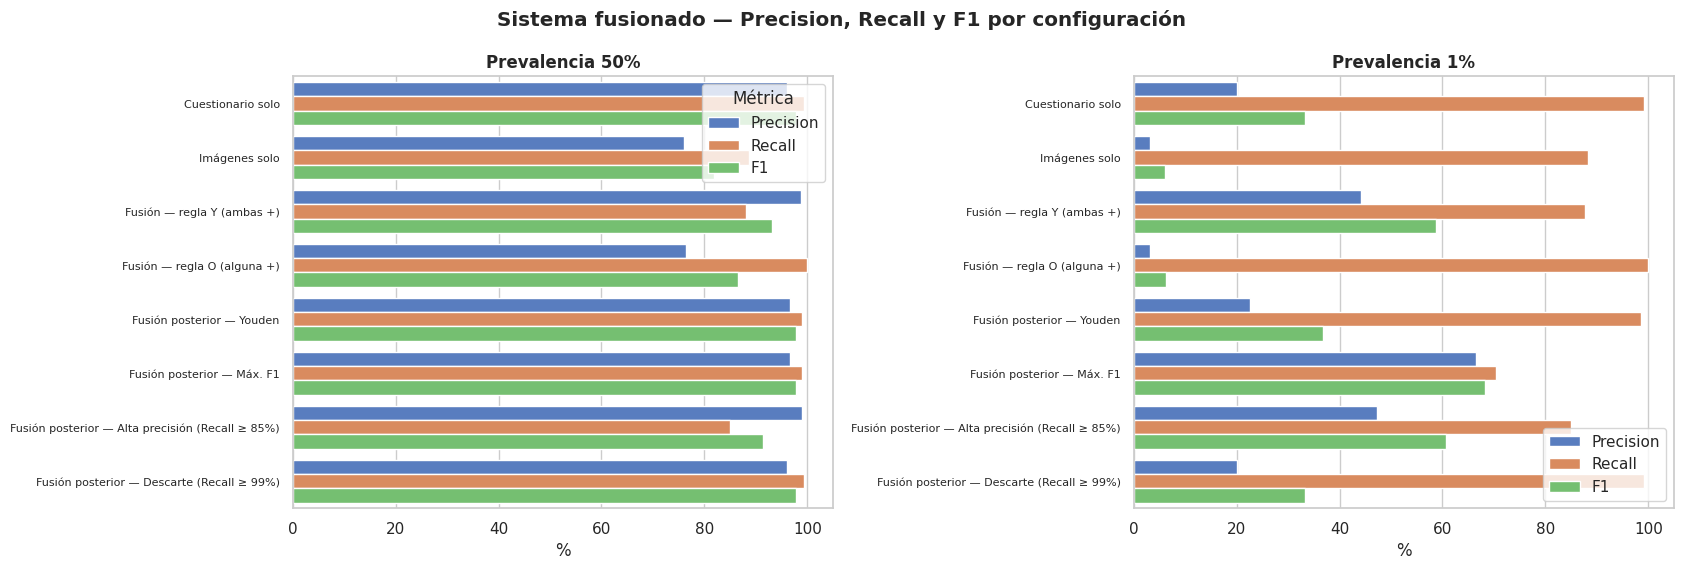

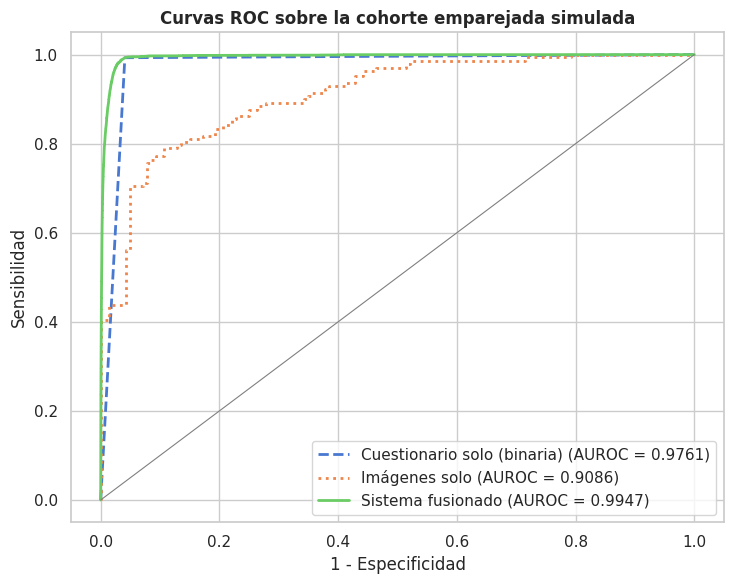

Deliverables in /content/drive/MyDrive/asd-screening-audit/outputs/fusion_casoA
   fig1_metricas_configuraciones.png              210,367 bytes
   fig2_roc_fusion.png                            192,612 bytes
   referencia_allison.csv                           2,647 bytes
   resumen_fusion_casoA.json                        1,889 bytes
   sensibilidad_fase2b.csv                          2,659 bytes
   sensibilidad_suavizado_LR.csv                   22,277 bytes
   tabla1_metricas_por_rama.csv                       271 bytes
   tabla1b_metricas_complementarias.csv               193 bytes
   tabla2_fusion_prev01.csv                         1,109 bytes
   tabla2_fusion_prev50.csv                         1,208 bytes
   tabla3_incertidumbre.csv                           665 bytes
   tabla4_dependencia_rho.csv                         385 bytes

>>> LATE FUSION COMPLETED.


In [10]:
# ==============================================================================
# CELL 8: Figures and export
# ==============================================================================
# --- Figure 1: Precision, Recall and F1 per configuration ---
fig, axes = plt.subplots(1, 2, figsize=(17, 5.8))
for ax, (prev, _) in zip(axes, PREVS):
    d = RES[prev].melt(id_vars='Configuration', value_vars=['Precision', 'Recall', 'F1'],
                       var_name='Metric', value_name='Value')
    d['Value'] *= 100
    sns.barplot(data=d, y='Configuration', x='Value', hue='Metric', ax=ax)
    ax.set_xlim(0, 105); ax.set_xlabel("%"); ax.set_ylabel("")
    ax.set_title(f"Prevalence {prev*100:.0f}%", fontweight='bold')
    ax.tick_params(axis='y', labelsize=8)
axes[1].legend(loc='lower right')
plt.suptitle("Fused system — Precision, Recall and F1 per configuration", fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "fig1_metricas_configuraciones.png"), dpi=300)
plt.show()

# --- Figure 2: ROC curves at 1% prevalence ---
s = simular(0.01, 500_000, SE_A, SP_A, IMG, semilla=SEED + 9)
plt.figure(figsize=(7.5, 6))
for etq, sc, est in [("Questionnaire alone (binary)", s['q'], '--'),
                     ("Images alone", s['lr_raw'], ':'), ("Fused system", s['post'], '-')]:
    f_, t_, _ = roc_curve(s['y'], sc)
    plt.plot(f_, t_, est, lw=2, label=f"{etq} (AUROC = {roc_auc_score(s['y'], sc):.4f})")
plt.plot([0, 1], [0, 1], c='gray', lw=0.8)
plt.xlabel("1 - Specificity"); plt.ylabel("Sensitivity")
plt.title("ROC curves on the simulated paired cohort", fontweight='bold')
plt.legend(loc='lower right'); plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "fig2_roc_fusion.png"), dpi=300)
plt.show()

# --- Export ---
RES[0.50].to_csv(os.path.join(OUTPUTS_DIR, "tabla2_fusion_prev50.csv"), index=False)
RES[0.01].to_csv(os.path.join(OUTPUTS_DIR, "tabla2_fusion_prev01.csv"), index=False)
tabla_ref.to_csv(os.path.join(OUTPUTS_DIR, "referencia_allison.csv"), index=False)
if tabla_2b is not None:
    tabla_2b.to_csv(os.path.join(OUTPUTS_DIR, "sensibilidad_fase2b.csv"), index=False)
tabla_inc.to_csv(os.path.join(OUTPUTS_DIR, "tabla3_incertidumbre.csv"), index=False)
tabla_rho.to_csv(os.path.join(OUTPUTS_DIR, "tabla4_dependencia_rho.csv"), index=False)

resumen_json = {
    'naturaleza': ('The fused system is evaluated on a SIMULATED paired cohort built '
                   'from the real outputs of each branch. There are no subjects with both modalities.'),
    'ramas': {
        'cuestionario': 'case A: XGBoost on the 10 items, hold-out n=%d' % len(ho),
        'imagenes': 'Phase 2: frozen EfficientNetV2B0 + calibrated XGBoost, test n=%d' % len(im)},
    'parametros': {
        'caso_A_corregido': {'Se': round(SE_A, 4), 'Sp': round(SP_A, 4),
                             'LR+': round(razones(SE_A, SP_A)[0], 3), 'LR-': round(razones(SE_A, SP_A)[1], 4)},
        'allison_referencia': {'Se': SE_L, 'Sp': SP_L,
                               'LR+': round(razones(SE_L, SP_L)[0], 3), 'LR-': round(razones(SE_L, SP_L)[1], 4)},
        'imagenes_fase2': {'Se': round(SE_I, 4), 'Sp': round(SP_I, 4), 'AUROC': round(IMG['auc'], 4),
                           'umbral_p': round(IMG['thr_p'], 4)}},
    'metricas_por_rama': tabla_ramas.round(4).to_dict(orient='records'),
    'auroc_fusion_formula': round(float(lex_auc(SE_A, SP_A, IMG['auc'])), 4),
    'advertencias': [
        'The case A metrics are inflated: the cohort label derives from the instrument rule. Read as an upper bound.',
        'The AND and OR rules and the product of likelihood ratios assume conditional independence between branches.',
        'The image branch shares capture artifacts between training and test; its figures are optimistic in the field.',
        'The probability-fusion thresholds are chosen on the simulated cohort: they are illustrative, not validated.',
        'The population prevalence in Peru is not known precisely.',
        'No configuration justifies communicating a diagnosis: the appropriate output is a risk category with professional referral.'],
}
with open(os.path.join(OUTPUTS_DIR, "resumen_fusion_casoA.json"), 'w') as f:
    json.dump(resumen_json, f, indent=2, ensure_ascii=False)

print("Deliverables in", OUTPUTS_DIR)
for a in sorted(os.listdir(OUTPUTS_DIR)):
    print(f"   {a:<44}{os.path.getsize(os.path.join(OUTPUTS_DIR, a)):>10,} bytes")
print("\n>>> LATE FUSION COMPLETED.")

---
## 9. How to Report These Results

**What can be stated**

- Each branch, separately, with its five metrics and its intervals, measured on held-out sets.
- That fusion improves the ranking (AUROC) relative to each branch and that, with the AND rule, it raises precision at the cost of recall.
- The magnitude of the effect of violating conditional independence (section 7).

**What must be declared as a limitation**

1. The fused system was evaluated on a **simulated cohort**; there is no validation with real subjects who have both modalities.
2. The **case A metrics are an upper bound**: the cohort label was derived from the instrument's rule. The reference with Allison et al. (2012) is the representative reading.
3. The image branch **shares capture artifacts** between training and test (framing, color and context separate the classes on their own), so its figures are optimistic in the field.
4. At low prevalence **precision is low** in any configuration. It is a property of screening for infrequent conditions, not a defect of the model.
5. With case A, the Youden point of the fusion coincides with that of the questionnaire alone; the contribution of the image lies in the ranking and in the more demanding operating points.

**System output:** a risk category with referral to professional evaluation, never a probability presented as a diagnosis.